In [141]:
import os

os.environ["HSA_OVERRIDE_GFX_VERSION"] = "10.3.0"

In [142]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

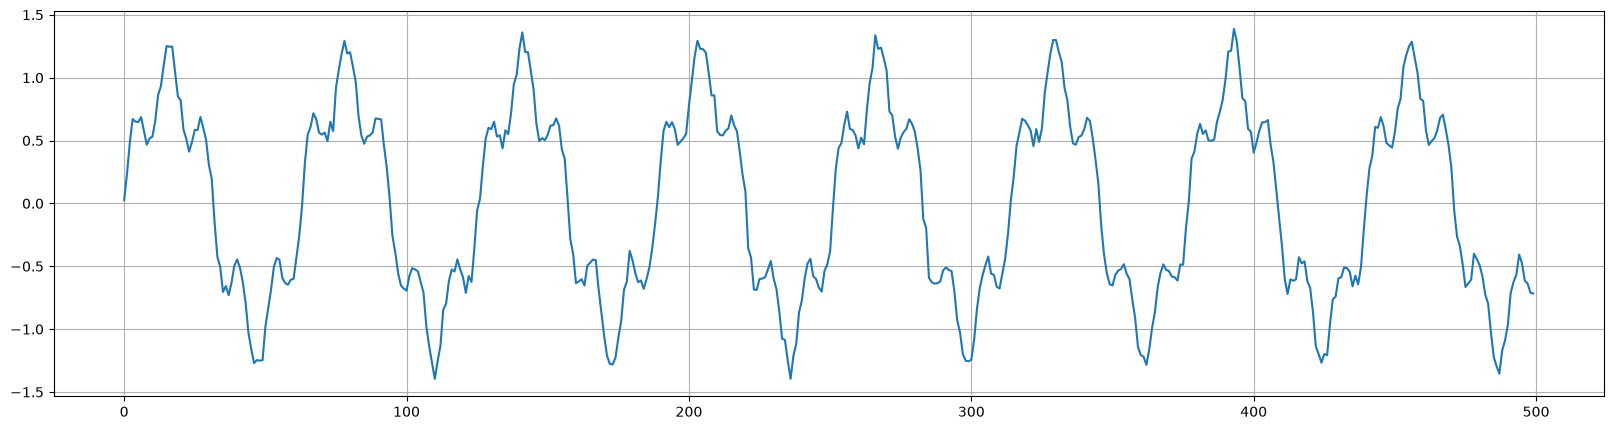

In [143]:
np.random.seed(42)
torch.manual_seed(42)

N = 2000
tt = np.arange(N)
signal = np.sin(0.1 * tt) + 0.3 * np.sin(0.5 * tt) + 0.05 * np.random.randn(N)

plt.figure(figsize=(20,5))
plt.plot(signal[:500])
plt.grid()
plt.show()

In [144]:
T = 50

def make_windows(series, T):
    X, y = [], []
    for i in range(len(series) - T):
        X.append(series[i : i + T])
        y.append(series[i + T])
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)

X, y = make_windows(signal, T)
X.shape, y.shape

((1950, 50), (1950,))

In [145]:
split = int(0.8 * len(X))
X_train, X_val = X[:split], X[split:]
y_train, y_val = y[:split], y[split:]

In [146]:
mu, sigma = X_train.mean(), X_train.std()
X_train = (X_train - mu) / sigma
X_val   = (X_val - mu) / sigma
y_train = (y_train - mu) / sigma
y_val   = (y_val - mu) / sigma

In [147]:
from torch.utils.data import TensorDataset, DataLoader

def to_tensors(Xa, ya):
    # (N, T) -> (N, T, 1)
    xb = torch.from_numpy(Xa).unsqueeze(-1)
    yb = torch.from_numpy(ya).unsqueeze(-1)   # (N, 1)
    return TensorDataset(xb, yb)

train_ds = to_tensors(X_train, y_train)
val_ds = to_tensors(X_val, y_val)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)

In [ ]:
class SimpleRNNRegressor(nn.Module):
    def __init__(self, input_size=1, hidden_size=32, num_layers=1):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True)
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        #out, h = self.rnn(x)            # out: (B, T, H), _ — неиспользуемое h_n
        out, (h, c) = self.lstm(x)
        return self.fc(out[:, -1, :])

device = "cuda" if torch.cuda.is_available() else "cpu"
model = SimpleRNNRegressor().to(device)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [149]:
def run_epoch(model, loader, train=True):
    model.train(train)
    total = 0.0

    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        loss = loss_fn(out, yb)

        if train:
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
        total += loss.item() * len(xb)
    return total / len(loader.dataset)

In [150]:
train_hist, val_hist = [], []
EPOCHS = 40

for ep in range(1, EPOCHS + 1):
    tr = run_epoch(model, train_loader, train=True)
    va = run_epoch(model, val_loader, train=False)
    train_hist.append(tr); val_hist.append(va)
    if ep % 5 == 0 or ep == 1:
        print(f"epoch {ep:2d}  train MSE={tr:.5f}  val MSE={va:.5f}")

epoch  1  train MSE=0.90228  val MSE=0.71714
epoch  5  train MSE=0.11726  val MSE=0.11201
epoch 10  train MSE=0.03293  val MSE=0.02730
epoch 15  train MSE=0.00983  val MSE=0.00677
epoch 20  train MSE=0.00868  val MSE=0.00613
epoch 25  train MSE=0.00601  val MSE=0.00643
epoch 30  train MSE=0.00612  val MSE=0.00569
epoch 35  train MSE=0.00648  val MSE=0.00570
epoch 40  train MSE=0.00612  val MSE=0.00656


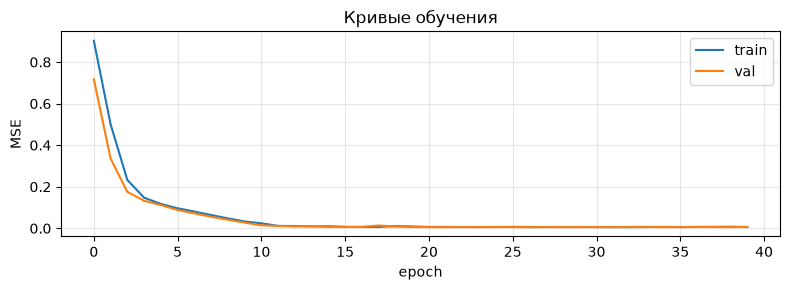

In [151]:
plt.figure(figsize=(8, 3))
plt.plot(train_hist, label="train")
plt.plot(val_hist,   label="val")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(); plt.grid(alpha=.3)
plt.title("Кривые обучения")
plt.tight_layout(); plt.show()

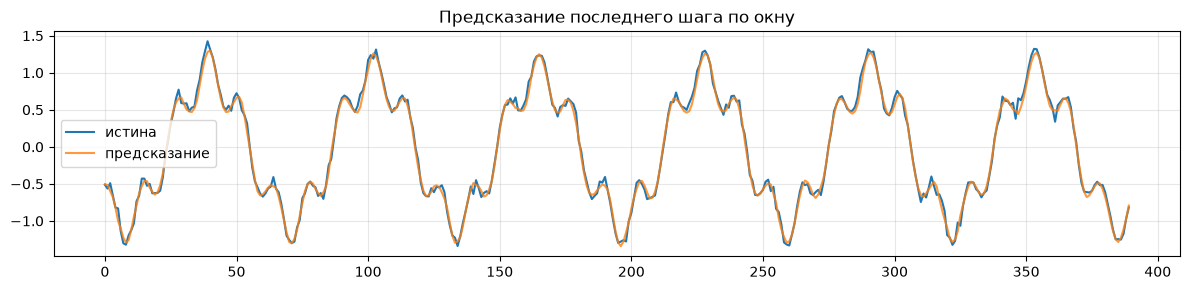

RMSE в исходных единицах: 0.0599


In [152]:
model.eval()
with torch.no_grad():
    xb = torch.from_numpy(X_val).unsqueeze(-1).to(device)
    pred = model(xb).cpu().numpy().squeeze(-1)   # (N_val,)

# возвращаемся из нормализованного масштаба
pred_real = pred * sigma + mu
true_real = y_val * sigma + mu

plt.figure(figsize=(12, 3))
plt.plot(true_real, label="истина")
plt.plot(pred_real, label="предсказание", alpha=.8)
plt.legend(); plt.grid(alpha=.3)
plt.title("Предсказание последнего шага по окну")
plt.tight_layout(); plt.show()

mse_real = np.mean((pred_real - true_real) ** 2)
print(f"RMSE в исходных единицах: {np.sqrt(mse_real):.4f}")

RMSE RNN: 0.0732